# `A_shock.ipynb`, corrected: a TFP shock (3%)

Same experiment and same plots as [`A_shock.ipynb`](A_shock.ipynb) — optimal policy against no policy
change, with and without time to build — with five corrections. Everything else, including
the calibration and the shock, is unchanged.

**1. Consumption is valued physically.** `tprod` is $\beta^{\tau} c(\tau+N)$, so the
nominal discount factor sits inside the quantity fed to the household. It is a discount
factor, not goods. Writing $\tilde A$ for the CES aggregate of $\beta^\tau z$ and $Z$ for
the aggregate of the physical $z$ alone, the correction subtracts
$d_t = \log\tilde A_t - \log Z_t$.

**2. What is plotted is now consumption.** The original plots `c_hat`, the solution of the
Euler equation, and labels it output. That object is the *gap*; consumption is the gap plus
the natural level. So $c_t = x_t + \varphi_{ya}a_t - d_t$, physically valued.

**3. The rate matrix no longer forgets.** `interest_rate_list[0:n, :n] = arr2d` leaves every
row from $n$ onward at $\rho$, so a firm delivering at $t\ge n$ discounts at $\rho$ even
when its entire production window sat inside the policy period. With mean $\tau\approx2.9$
that mismeasures $\beta^\tau$ by several per cent. Rows now carry the rates that actually
prevailed.

**4. The rate sequence is optimised, not enumerated.** The original takes `argmin` over
`itertools.product` on a 6-point grid. Here L-BFGS-B on $[0,5\%]$ per period, three starting
points, horizon grown until the objective stops improving.

**5. Impact inflation is counted.** $P_t = 1/\tilde A_t$, so $\pi_t = -(a_t - a_{t-1})$, and
the code set $\pi_0 = 0$ for want of an $a_{-1}$ in the array. But $a_{-1}$ exists in the
model: period $-1$ is the pre-shock steady state, which is the level $a_t$ is normalised to
($a_{T-1}=0$). So $\pi_0 = -a_0$. Under time to build $a_0 \approx -0.007\%$ and this is
invisible. With **no** time to build every firm reprices at $t=0$, the whole $3\%$ moves on
impact, and the old code recorded none of it — the inflation panel showed zero at $t=0$ and
a spurious-looking $-3\%$ at $t=1$, which is only the price level falling back.

The objective is kept as the original's, $\sum_t c_t^2 + \sum_t \pi_t^2$ — only now $c$ is
consumption rather than the gap, and the $\pi$ sum starts at $t=0$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

Unchanged.

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE = 0.01
sigma = 5
gamma = 1.0                      # the original's `sigma`/`theta` in the Euler equation
eta = 2.0
PHI_YA = (1 + eta) / (gamma + eta)

beta = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1 = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1
W = 1

SHOCK = 0.97          # staggered TFP multiplier
D_SHOCK = 0.0       # demand shock at t=0
T = 30
PI_WEIGHT = 1.0      # weight on sum(pi^2) in the loss.  1.0 = the original notebooks;
                     # 0.0 = the planner's objective, which prices only consumption.

SHOCKNAME = 'TFP shock (3%)'
FIGPREFIX = 'semi_endo_fixed_A'

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA}, rho={rho:.4f}')
print(f'TFP shock={SHOCK}, demand shock={D_SHOCK}')

gamma=1.0, eta=2.0, phi_ya=1.0, rho=0.0100
TFP shock=0.97, demand shock=0.0


In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
optimal_c_value = np.min(c_list[np.where(np.abs(tau_diff - 1) ==
                                         np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * optimal_c_value)
tau = -1 / np.log(beta * optimal_c_value) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * optimal_c_value)**tc * (tc + N)
pf = (beta * optimal_c_value)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS = len(tvals)
Z_PHYS = optimal_c_value * (tvals + N_array)      # physical output per firm, no discount

print(f'c = {optimal_c_value:.7f}   mean tau = {tau.mean():.4f}   firms = {NFIRMS}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_43629/3708484212.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   mean tau = 2.8885   firms = 269


In [4]:
def generate_pattern_array_with_extra_rows(tau, shock=SHOCK):
    """Staggering matrix, unchanged from the original."""
    tau = np.asarray(tau)
    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing = len(set(range(int(max(tau)) + 1)) - set(tau))
    A = np.ones((m + 2, n + missing), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms = tau[tau == i - 1]
        for j in range(len(firms)):
            A[i, n - i - j - count] = shock
        if len(firms) > 1:
            count += len(firms) - 1
    return np.vstack([A, np.ones(n + missing)])[:, 0:n - int(np.min(tau))]


A_PATTERN = generate_pattern_array_with_extra_rows(tau)
print('staggering matrix:', A_PATTERN.shape)

staggering matrix: (16, 269)


## 2. The model, with corrections 1–3

`rate_matrix` is where correction 3 lives. The original fills only the top-left block, so
rows beyond the policy window silently revert to $\rho$; here row $t$ carries
$i_{t-k}$ for every $k$, which is the rate that actually applied.

In [5]:
def rate_matrix(r, T=T, truncated=False):
    """Row t = the rates a firm delivering at t discounts over, most recent first."""
    L = len(r)
    ip = np.ones(T) * rho
    ip[:L] = np.asarray(r, float)
    irl = np.ones((T, T)) * rho
    if truncated:                              # the original's construction
        blk = np.full((L, L), rho)
        for i in range(L):
            blk[i, :i + 1] = np.asarray(r, float)[i::-1]
        irl[0:L, :L] = blk
    else:                                      # corrected: rows keep their own history
        for t in range(T):
            for k in range(T):
                irl[t, k] = ip[t - k] if t - k >= 0 else rho
    return irl


def aggregates(r, T=T, time_to_build=True, truncated=False):
    """(a_nat, d, pi) -- measured TFP, its discount content, and inflation."""
    irl = rate_matrix(r, T, truncated)
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    tv = tvals if time_to_build else np.zeros_like(tvals)
    disc = ce[:, tv]

    prod_shock = np.ones((T, NFIRMS))
    if SHOCK != 1.0:
        if time_to_build:
            prod_shock[0:15] = A_PATTERN[1:]
        else:
            prod_shock[0, :] = SHOCK           # everyone reprices at once

    tprod = disc * Z_PHYS * prod_shock
    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))
    Z_t = np.sum((Z_PHYS * prod_shock)**(sigma - 1), axis=1)**(1 / (sigma - 1))

    a_nat = np.log(A_til) - np.log(A_til)[-1]
    d = np.log(A_til) - np.log(Z_t); d = d - d[-1]

    # Correction 5: impact inflation.  P = 1/Atil, so pi_t = -(a_t - a_{t-1}).  There is no
    # a_{-1} in the array, but there is one in the model: period -1 is the pre-shock steady
    # state, which is exactly the level a_nat is normalised to (a_nat[-1] = 0).  Leaving
    # pi[0] = 0 therefore drops the on-impact price jump.  Under time to build a_nat[0] is
    # ~0.007% and it is invisible; with no time to build the whole 3% moves at t=0, so the
    # entire inflation response was being discarded and only its t=1 reversal recorded.
    pi = np.zeros(T)
    pi[0] = -a_nat[0]
    pi[1:] = -(a_nat[1:] - a_nat[:-1])
    return a_nat, d, pi


def solve(r, T=T, time_to_build=True, truncated=False):
    """Euler equation, then consumption = gap + natural level, physically valued."""
    a_nat, d, pi = aggregates(r, T, time_to_build, truncated)
    ip = np.ones(T) * rho
    ip[:len(r)] = np.asarray(r, float)
    dem = np.zeros(T); dem[0] = D_SHOCK
    pi_fwd = np.r_[pi[1:], 0.0]

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - rho + dem[t])
    x = x[:T]

    c_meas = x + PHI_YA * a_nat            # consumption, discount still inside
    c_phys = c_meas - d                    # correction 1
    return dict(c=c_phys, c_meas=c_meas, x=x, pi=pi, a=a_nat, d=d, i=ip)


def loss(r, time_to_build=True, adjusted=True, truncated=False, pi_weight=None):
    """sum c^2 + w * sum pi^2 on the corrected consumption series.  w=1 is the original."""
    w = PI_WEIGHT if pi_weight is None else pi_weight
    s = solve(r, T, time_to_build, truncated)
    cc = s['c'] if adjusted else s['c_meas']
    return float(np.sum(cc**2) + w * np.sum(s['pi']**2))

## 3. Correction 4: optimise instead of enumerate

In [6]:
SEEDS = [lambda L: np.ones(L) * rho,
         lambda L: np.linspace(0.005, 0.015, L),
         lambda L: np.full(L, 0.005)]


def escalate(time_to_build=True, adjusted=True, L_range=range(1, 13),
             bounds=(0.0, 0.05), tol=1e-12, verbose=True, pi_weight=None):
    hist = {}
    if verbose:
        print(f'{"L":>3} {"loss":>18}   optimal sequence')
        print('-' * 78)
    for L in L_range:
        best = None
        for seed in SEEDS:
            res = minimize(lambda r: loss(r, time_to_build, adjusted,
                                          pi_weight=pi_weight), seed(L),
                           method='L-BFGS-B', bounds=[bounds] * L,
                           options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
            if best is None or res.fun < best.fun:
                best = res
        hist[L] = (best.x.copy(), float(best.fun))
        if verbose:
            print(f'{L:>3} {best.fun:>18.10e}   {np.round(best.x[:7], 5)}'
                  f'{" ..." if L > 7 else ""}')
    bestval = min(v[1] for v in hist.values())
    L_conv = min(L for L, v in hist.items() if v[1] - bestval < tol)
    if verbose:
        print(f'\n-> best loss {bestval:.6e}, first reached at L = {L_conv}')
    return hist, L_conv


def original_grid(time_to_build=True):
    """The original's enumeration, scored on the original's (unadjusted) objective."""
    sl = 4 if time_to_build else 5
    rc = np.linspace(0, 0.0125, 6)
    arr = np.array(list(itertools.product(rc, repeat=sl)))
    L = np.array([loss(rr, time_to_build, adjusted=False, truncated=True) for rr in arr])
    k = int(np.argmin(L))
    return arr[k], arr.shape

## 4. How much does correction 3 alone matter?

Before solving, size the truncation on its own: same rate path, two constructions.

In [7]:
probe = np.array([0.0, 0.005, 0.0125, 0.0])
for lab, ttb in [('exogenous time to build', True), ('no time to build', False)]:
    a1, d1, p1 = aggregates(probe, T, ttb, truncated=True)
    a2, d2, p2 = aggregates(probe, T, ttb, truncated=False)
    print(f'{lab}:')
    print(f'   max |a_truncated - a_corrected| = {np.max(np.abs(a1 - a2)):.3e}')
    print(f'   max |d_truncated - d_corrected| = {np.max(np.abs(d1 - d2)):.3e}')
    print(f'   loss truncated {loss(probe, ttb, True, True):.6e}  vs '
          f'corrected {loss(probe, ttb, True, False):.6e}')

exogenous time to build:
   max |a_truncated - a_corrected| = 9.766e-03
   max |d_truncated - d_corrected| = 9.766e-03
   loss truncated 2.283824e-03  vs corrected 2.002399e-03
no time to build:
   max |a_truncated - a_corrected| = 0.000e+00
   max |d_truncated - d_corrected| = 0.000e+00
   loss truncated 3.644001e-03  vs corrected 3.644001e-03


## 5. Results

In [8]:
results = {}
for lab, ttb in [('No time to build', False), ('Exogenous time to build', True)]:
    print('=' * 78); print(lab); print('=' * 78)
    h, L = escalate(time_to_build=ttb)
    r_opt = h[L][0]
    s_opt = solve(r_opt, T, ttb)
    s_base = solve(np.ones(3) * rho, T, ttb)
    r_old, shape_old = original_grid(ttb)
    s_old = solve(r_old, T, ttb)
    results[lab] = (r_opt, L, s_opt, s_base, s_old, r_old, shape_old)
    print()

No time to build
  L               loss   optimal sequence
------------------------------------------------------------------------------


  1   4.4482116242e-03   [0.]
  2   3.6298433248e-03   [0. 0.]
  3   3.3114750254e-03   [0. 0. 0.]
  4   3.3112641539e-03   [0.      0.      0.      0.00977]


  5   3.3112641539e-03   [0.      0.      0.      0.00977 0.01   ]


  6   3.3112641539e-03   [0.      0.      0.      0.00977 0.01    0.01   ]


  7   3.3112641539e-03   [0.      0.      0.      0.00977 0.01    0.01    0.01   ]


...

  8   8.9744126264e-05   [0.01441 0.00954 0.0008  0.00948 0.0071  0.01099 0.01031] ...


  9   8.9713362135e-05   [0.01441 0.00954 0.00079 0.00947 0.0071  0.01098 0.01029] ...


 10   8.9532596035e-05   [0.01441 0.00954 0.0008  0.00948 0.00711 0.01099 0.01032] ...


 11   8.9471435138e-05   [0.01441 0.00954 0.0008  0.00948 0.00711 0.01098 0.01031] ...


 12   8.9469827319e-05   [0.01441 0.00954 0.0008  0.00948 0.00711 0.01098 0.01031] ...

-> best loss 8.946983e-05, first reached at L = 12


In [9]:
w = 46
for lab, (r_opt, L, s_opt, s_base, s_old, r_old, shape_old) in results.items():
    print('=' * 80); print(lab); print('=' * 80)
    print(f'{"original enumeration, search space":<{w}}: {shape_old}')
    print(f'{"  its choice":<{w}}: {np.round(r_old, 5)}')
    print(f'{"corrected solver, free periods":<{w}}: {L}')
    print(f'{"  its choice":<{w}}: {np.round(r_opt[:8], 5)}')
    print()
    for nm, s in [('no policy change', s_base), ('original enumeration', s_old),
                  ('corrected solver', s_opt)]:
        print(f'{nm:<{w}}: loss = {np.sum(s["c"]**2) + np.sum(s["pi"]**2):.6e}   '
              f'peak |c| = {100*np.max(np.abs(s["c"])):.4f}%')
    print(f'{"optimum on a bound of [0, 0.05]":<{w}}: '
          f'{bool(np.any(np.isclose(r_opt, 0.0) | np.isclose(r_opt, 0.05)))}')
    print(f'{"peak |d| under the optimum":<{w}}: {np.max(np.abs(s_opt["d"])):.4e}')
    print(f'{"consumption: measured vs physical, peak":<{w}}: '
          f'{100*np.max(np.abs(s_opt["c_meas"])):.4f}% vs '
          f'{100*np.max(np.abs(s_opt["c"])):.4f}%')
    print()

No time to build
original enumeration, search space            : (7776, 5)
  its choice                                  : [0.   0.   0.   0.01 0.01]
corrected solver, free periods                : 4
  its choice                                  : [0.      0.      0.      0.00977]

no policy change                              : loss = 5.566580e-03   peak |c| = 6.0918%
original enumeration                          : loss = 3.311475e-03   peak |c| = 3.0918%
corrected solver                              : loss = 3.311264e-03   peak |c| = 3.0689%
optimum on a bound of [0, 0.05]               : True
peak |d| under the optimum                    : 0.0000e+00
consumption: measured vs physical, peak       : 3.0689% vs 3.0689%

Exogenous time to build
original enumeration, search space            : (1296, 4)
  its choice                                  : [0.0125 0.01   0.0025 0.01  ]
corrected solver, free periods                : 12
  its choice                                  : [0.01441 0.

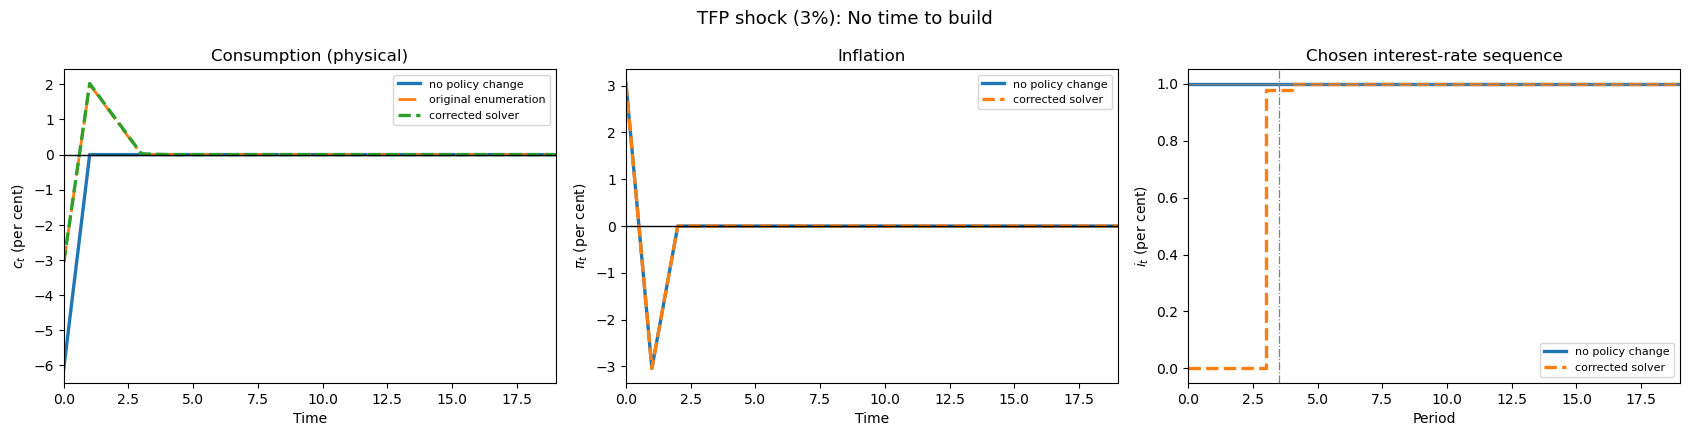

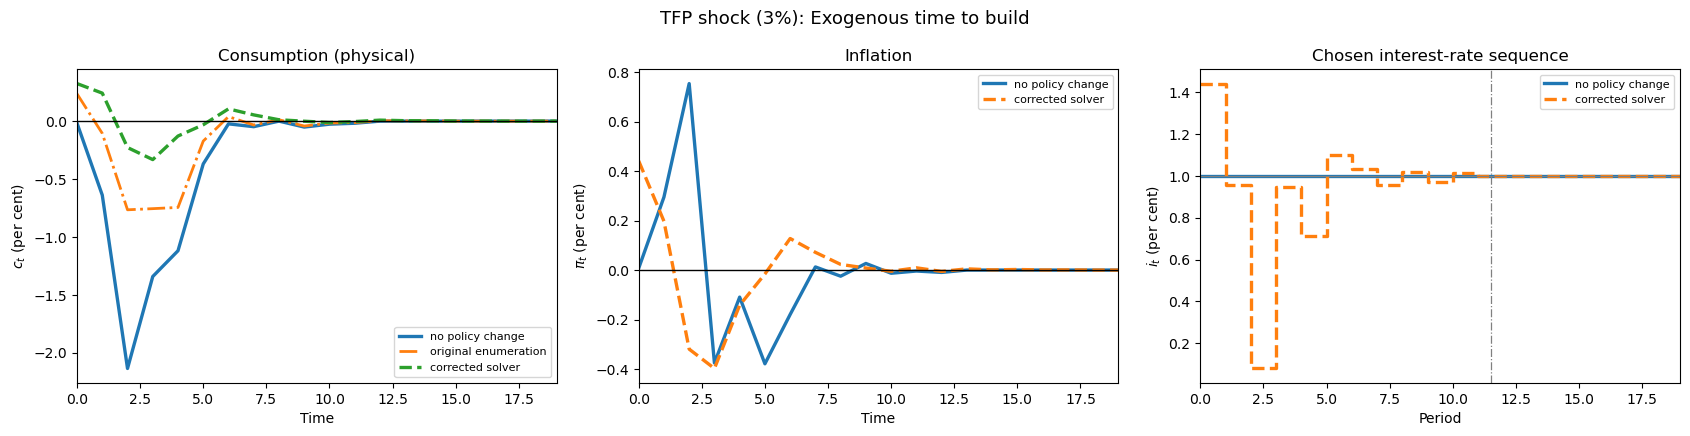

In [10]:
for lab, (r_opt, L, s_opt, s_base, s_old, r_old, shape_old) in results.items():
    H = 20
    t = np.arange(H)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

    ax = axes[0]
    ax.plot(t, 100 * s_base['c'][:H], lw=2.4, label='no policy change')
    ax.plot(t, 100 * s_old['c'][:H], lw=2.0, ls='-.', label='original enumeration')
    ax.plot(t, 100 * s_opt['c'][:H], lw=2.4, ls='--', label='corrected solver')
    ax.axhline(0, color='k', lw=1.0); ax.set_xlim(0, H - 1)
    ax.set_xlabel('Time'); ax.set_ylabel('$c_t$ (per cent)')
    ax.set_title('Consumption (physical)'); ax.legend(fontsize=8)

    ax = axes[1]
    ax.plot(t, 100 * s_base['pi'][:H], lw=2.4, label='no policy change')
    ax.plot(t, 100 * s_opt['pi'][:H], lw=2.4, ls='--', label='corrected solver')
    ax.axhline(0, color='k', lw=1.0); ax.set_xlim(0, H - 1)
    ax.set_xlabel('Time'); ax.set_ylabel(r'$\pi_t$ (per cent)')
    ax.set_title('Inflation'); ax.legend(fontsize=8)

    ax = axes[2]
    ax.step(t, 100 * s_base['i'][:H], where='post', lw=2.4, label='no policy change')
    ax.step(t, 100 * s_opt['i'][:H], where='post', lw=2.4, ls='--',
            label='corrected solver')
    ax.axhline(100 * rho, color='grey', lw=0.9)
    if L < H:
        ax.axvline(L - 0.5, color='grey', lw=0.9, ls='-.')
    ax.set_xlim(0, H - 1); ax.set_xlabel('Period'); ax.set_ylabel('$i_t$ (per cent)')
    ax.set_title('Chosen interest-rate sequence'); ax.legend(fontsize=8)

    fig.suptitle(f'{SHOCKNAME}: {lab}', fontsize=13)
    plt.tight_layout()
    tag = 'notb' if lab.startswith('No') else 'ttb'
    plt.savefig(f'../{FIGPREFIX}_{tag}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 6. The inflation term is what separates this from the planner

`semi_endo/planner_consumption_deviation.ipynb` maximises household utility, which contains
no inflation term at all — in this model there is no price-dispersion cost, so inflation is
free and the planner spends it freely to hold consumption at its efficient level. The loss
here prices inflation at weight 1, inherited from `A_shock.ipynb`.

Sweeping that weight moves this notebook continuously onto the planner's answer.

In [11]:
print(f'{"pi weight":>10}{"peak |c|":>13}{"peak |pi|":>13}{"sum c^2":>14}{"sum pi^2":>14}')
print('-' * 64)
for w in [1.0, 0.5, 0.1, 0.0]:
    h, L = escalate(time_to_build=True, L_range=range(1, 13), verbose=False, pi_weight=w)
    s = solve(h[L][0], T, True)
    print(f'{w:>10.2f}{100*np.max(np.abs(s["c"])):>12.4f}%{100*np.max(np.abs(s["pi"])):>12.4f}%'
          f'{np.sum(s["c"]**2):>14.3e}{np.sum(s["pi"]**2):>14.3e}')

print('\n-> at weight 0 the objective IS the planner\'s: consumption is driven to the')
print('   efficient level and whatever inflation that takes is accepted.')
print('   At weight 1 some consumption deviation is traded for less inflation.')

 pi weight     peak |c|    peak |pi|       sum c^2      sum pi^2
----------------------------------------------------------------


      1.00      0.3322%      0.4411%     3.580e-05     5.367e-05


      0.50      0.2146%      0.5281%     1.458e-05     8.312e-05


      0.10      0.1216%      0.6633%     2.467e-06     1.261e-04


      0.00      0.1180%      0.7246%     1.662e-06     1.429e-04

-> at weight 0 the objective IS the planner's: consumption is driven to the
   efficient level and whatever inflation that takes is accepted.
   At weight 1 some consumption deviation is traded for less inflation.


## Summary

Same experiment as `A_shock.ipynb`, five corrections applied.

1. **Consumption is physical.** $\beta^\tau$ is a discount factor and was being counted as
   goods. Subtracting $d_t=\log\tilde A_t-\log Z_t$ removes it. The measured-vs-physical
   peak is reported above; the difference is the part that made rate cuts look like free
   output.

2. **The plotted series is consumption, not the gap.** The original plots the Euler
   solution `c_hat` and labels it output. Consumption is $x_t+\varphi_{ya}a_t-d_t$.

3. **The rate matrix keeps its history.** `interest_rate_list[0:n,:n]` left rows beyond the
   policy window at $\rho$, so firms delivering just after the window discounted as if
   policy had never moved. Section 4 sizes it.

4. **The sequence is optimised.** L-BFGS-B with the horizon escalated, against the
   original's 6-point enumeration over 4–5 periods. The comparison table shows both.

5. **Impact inflation is counted.** $\pi_0=-a_0$ rather than $0$. This is what made the
   no-time-to-build case look like a TFP shock that causes no inflation: the entire $3\%$
   price jump happens at $t=0$ there and was being dropped, leaving only its reversal at
   $t=1$ on the plot. Note it does not change the chosen policy in that case — with
   $\tau\equiv0$ the discount block collapses to ones, so $\tilde A$ carries no
   interest-rate content and inflation is invariant to $i_t$; only the level of the loss
   moves. Under time to build $\pi_0$ does depend on $i_0$, so the optimum shifts slightly.

The inflation weight is now the parameter `PI_WEIGHT`, set to 1.0 to match the original.
Section 6 sweeps it; set it to 0 to reproduce the planner's answer exactly.

One thing deliberately left alone: the natural rate stays at $\rho$ (plus the demand shock),
as in the original, rather than picking up the $\gamma\,\Delta y^n$ term used in
`semi_endo/planner_adjusted_consumption.ipynb`. Adding it is a further change to the model
rather than a correction of the code, so it is left for you to decide.